# Feature Engineering and PCA for loan Approved CSV

Feature Engineering is the process of transforming raw data into meaningful features that improve model performance.

### Steps:
1. Handling Missing (Null) Values
2. Detecting and Treating Outliers
3. Feature Scaling
4. Encoding Categorical Data
5. Data Transformation

In [170]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder,MinMaxScaler,RobustScaler
import warnings
import matplotlib.pyplot as plt

In [171]:
warnings.filterwarnings('ignore')

In [172]:
df=pd.read_csv("loan_approved.csv")

In [173]:
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [174]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Loan_ID                 614 non-null    str    
 1   Gender                  601 non-null    str    
 2   Married                 611 non-null    str    
 3   Dependents              599 non-null    str    
 4   Education               614 non-null    str    
 5   Self_Employed           582 non-null    str    
 6   ApplicantIncome         614 non-null    int64  
 7   CoapplicantIncome       614 non-null    float64
 8   LoanAmount              592 non-null    float64
 9   Loan_Amount_Term        600 non-null    float64
 10  Credit_History          564 non-null    float64
 11  Property_Area           614 non-null    str    
 12  Loan_Status (Approved)  614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


In [175]:
df.isnull().sum()

Loan_ID                    0
Gender                    13
Married                    3
Dependents                15
Education                  0
Self_Employed             32
ApplicantIncome            0
CoapplicantIncome          0
LoanAmount                22
Loan_Amount_Term          14
Credit_History            50
Property_Area              0
Loan_Status (Approved)     0
dtype: int64

## 1️⃣ Handling Missing (Null) Values

Missing values can cause errors or bias in model training. Let's check and handle them.
- **Dropping columns:** dropna(), drop(), drop_duplicates()
- **Filling/Imputing:** fillna(), or impute manually


In [176]:
df.duplicated().sum()   #To get the number of duplicate rows

np.int64(0)

In [177]:
df.drop_duplicates()    #To remove or delete or drop duplicate rows from data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [178]:
df.shape

(614, 13)

In [179]:
#df.drop('Gender',axis=1,inplace=True)
df.dropna()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [180]:
#Null columns: 'Gender','Dependents','Self_Employed','LoanAmount','Loan_Amount_Term','Credit_History'

#df.fillna(value = {'Gender': 'F','LoanAmount':np.mean(df.LoanAmount),'Credit_History':df.Credit_History.median()})
#df.fillna(0)

#df.loc[df.LoanAmount.isnull(),'LoanAmount'] = df.LoanAmount.mean()  # - Each individual column can be imputed separately

### 1.find Null columns in the dataset

In [181]:
df.Loan_Amount_Term.value_counts()

Loan_Amount_Term
360.0    512
180.0     44
480.0     15
300.0     13
240.0      4
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64

In [182]:
# handle the null columns
# method 1:
df.fillna(value = {'Gender': 'Male',
                   'LoanAmount':df.LoanAmount.median(),
                   'Credit_History':df.Credit_History.median(),
                   'Dependents':'0',
                   'Self_Employed':'No',
                   'Loan_Amount_Term':360.0},inplace=True)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [183]:
# after handlling check null values are present
df.isnull().sum()

Loan_ID                   0
Gender                    0
Married                   3
Dependents                0
Education                 0
Self_Employed             0
ApplicantIncome           0
CoapplicantIncome         0
LoanAmount                0
Loan_Amount_Term          0
Credit_History            0
Property_Area             0
Loan_Status (Approved)    0
dtype: int64

In [184]:
df.Married.value_counts()

Married
Yes    398
No     213
Name: count, dtype: int64

In [185]:
# method 2: by using loc

df.loc[df.Married.isnull(),'Married'] = 'Yes'

# method 3:based on the filter/condition as shown below
#df.loc[(df.Married.isnull()&df.Dependents=='0'),'Married']='No'
#df.loc[(df.Married.isnull()&df.Dependents!='0'),'Married']='Yes'
#df.loc[(df.Married.isnull()&df.CoapplicantIncome==0),'Married']='No'
#df.loc[(df.Married.isnull()&df.CoapplicantIncome!=0),'Married']='Yes'

In [186]:
df.isnull().sum()

Loan_ID                   0
Gender                    0
Married                   0
Dependents                0
Education                 0
Self_Employed             0
ApplicantIncome           0
CoapplicantIncome         0
LoanAmount                0
Loan_Amount_Term          0
Credit_History            0
Property_Area             0
Loan_Status (Approved)    0
dtype: int64

---
--- 

## 2️⃣ Detecting and Handling Outliers

Outliers are extreme values that can distort data analysis.

### 1.IQR Method

In [187]:
# Removing Outliers using IQR

Q1 = df['LoanAmount'].quantile(0.25)
Q3 = df['LoanAmount'].quantile(0.75)

IQR = Q3 - Q1

# Lower and Upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound :", lower_bound)
print("Upper Bound :", upper_bound)


# Store original values
before = df['LoanAmount'].copy()

# Capping outliers using winsorization
df.loc[df['LoanAmount'] < lower_bound, 'LoanAmount'] = lower_bound
df.loc[df['LoanAmount'] > upper_bound, 'LoanAmount'] = upper_bound

# Compare before and after
print("\nBefore and After Handling")

comparison = pd.DataFrame({
    'Before': before,
    'After': df['LoanAmount']
})

print(comparison[comparison['Before'] != comparison['After']])# Cap the outliers method 2
#df['LoanAmount'] = df['LoanAmount'].clip(lower, upper)
#df.describe()

Lower Bound : 3.5
Upper Bound : 261.5

Before and After Handling
     Before  After
5     267.0  261.5
9     349.0  261.5
21    315.0  261.5
34    320.0  261.5
54    286.0  261.5
67    312.0  261.5
83    265.0  261.5
126   370.0  261.5
130   650.0  261.5
135   290.0  261.5
155   600.0  261.5
161   275.0  261.5
171   700.0  261.5
177   495.0  261.5
233   280.0  261.5
253   279.0  261.5
258   304.0  261.5
260   330.0  261.5
278   436.0  261.5
308   480.0  261.5
324   300.0  261.5
325   376.0  261.5
333   490.0  261.5
351   308.0  261.5
369   570.0  261.5
372   380.0  261.5
381   296.0  261.5
391   275.0  261.5
409   360.0  261.5
432   405.0  261.5
487   500.0  261.5
506   480.0  261.5
514   311.0  261.5
523   480.0  261.5
525   400.0  261.5
536   324.0  261.5
561   600.0  261.5
572   275.0  261.5
592   292.0  261.5
600   350.0  261.5
604   496.0  261.5


<Axes: xlabel='LoanAmount'>

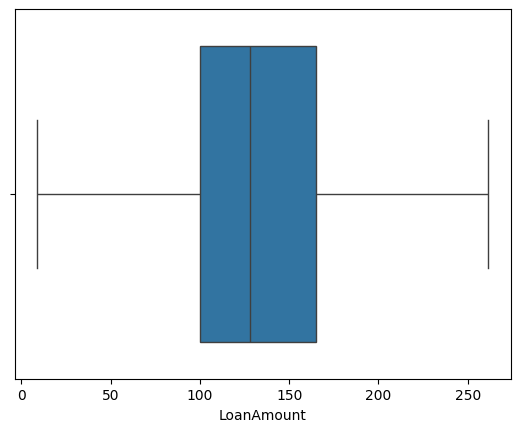

In [188]:
sns.boxplot(x=df.LoanAmount ,orient='h')

<Axes: xlabel='CoapplicantIncome'>

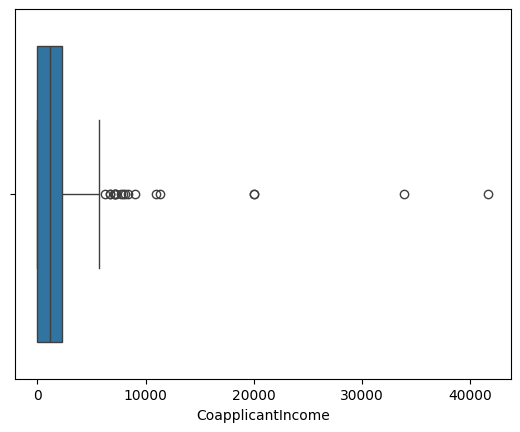

In [189]:

sns.boxplot(x=df.CoapplicantIncome,orient='h')

### 3.EMPERICLE Rule

In [190]:
col = 'ApplicantIncome'

mean = df[col].mean()
std = df[col].std()

lower_limit = mean - 3*std
upper_limit = mean + 3*std

std_outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)] #dataframe
print("Mean ± 3*STD Outliers:\n", std_outliers.ApplicantIncome)

#Manually setting limits
df.loc[df.ApplicantIncome>20000,'ApplicantIncome'] = 20000

print("manual setting and verify for row index",df.loc[126,'ApplicantIncome'])

Mean ± 3*STD Outliers:
 126    23803
155    39999
171    51763
183    33846
185    39147
333    63337
409    81000
443    37719
Name: ApplicantIncome, dtype: int64
manual setting and verify for row index 20000


### 4.Z Score

In [191]:
from scipy import stats
import numpy as np
import pandas as pd

# Calculate Z-score
df['zscore'] = stats.zscore(df['CoapplicantIncome'])

# Outlier rows only
outliers = df[(df['zscore'] < -3) | (df['zscore'] > 3)]

print("Original Outliers")
print(outliers[['CoapplicantIncome', 'zscore']])

# Store same indexes
idx = outliers.index

# ---------------------------------------------------
# METHOD 1 : Mean Replacement
# ---------------------------------------------------

df_mean = df.copy()

mean_value = df_mean['CoapplicantIncome'].mean()

df_mean.loc[idx, 'CoapplicantIncome'] = mean_value

print("\nMean Replacement")
print(df_mean.loc[idx, ['CoapplicantIncome']])

# ---------------------------------------------------
# METHOD 2 : Median Replacement
# ---------------------------------------------------

df_median = df.copy()

median_value = df_median['CoapplicantIncome'].median()

df_median.loc[idx, 'CoapplicantIncome'] = median_value

print("\nMedian Replacement")
print(df_median.loc[idx, ['CoapplicantIncome']])

# ---------------------------------------------------
# METHOD 3 : Capping / Winsorization
# ---------------------------------------------------

df_cap = df.copy()

lower_limit = df_cap['CoapplicantIncome'].quantile(0.05)
upper_limit = df_cap['CoapplicantIncome'].quantile(0.95)

df_cap['CoapplicantIncome'] = np.where(
    df_cap['CoapplicantIncome'] > upper_limit,
    upper_limit,
    df_cap['CoapplicantIncome']
)

print("\nCapping / Winsorization")
print(df_cap.loc[idx, ['CoapplicantIncome']])

# ---------------------------------------------------
# METHOD 4 : Log Transformation
# ---------------------------------------------------

df_log = df.copy()

df_log['CoapplicantIncome'] = np.log1p(df_log['CoapplicantIncome'])

print("\nLog Transformation")
print(df_log.loc[idx, ['CoapplicantIncome']])

# ---------------------------------------------------
# METHOD 5 : Removing Outliers
# ---------------------------------------------------

df_remove = df[(df['zscore'] >= -3) & (df['zscore'] <= 3)]

print("\nAfter Removing Outliers")
print("Indexes Removed :", list(idx))

Original Outliers
     CoapplicantIncome     zscore
9              10968.0   3.196713
177            11300.0   3.310261
402            20000.0   6.285775
417            20000.0   6.285775
581            33837.0  11.018211
600            41667.0  13.696173

Mean Replacement
     CoapplicantIncome
9          1621.245798
177        1621.245798
402        1621.245798
417        1621.245798
581        1621.245798
600        1621.245798

Median Replacement
     CoapplicantIncome
9               1188.5
177             1188.5
402             1188.5
417             1188.5
581             1188.5
600             1188.5

Capping / Winsorization
     CoapplicantIncome
9               4997.4
177             4997.4
402             4997.4
417             4997.4
581             4997.4
600             4997.4

Log Transformation
     CoapplicantIncome
9             9.302828
177           9.332646
402           9.903538
417           9.903538
581          10.429340
600          10.637489

After Removing O

# 3.Transformation of skewed data

## Types Of Transformation

1. Scaling is also indirectly transforming the variable. Standardization, Normal MinMax, Robust scaling are the techniques used.
3. Logarithmic Transformation
4. Exponential Transformation
5. Box Cox Transformation
6. Square Root Transformation

In [192]:
# Find skewness of numerical columns
# =============================================
#  Understanding Skewness
# =============================================

# Skewness value interpretation:
# skew = 0   → Normal distribution
# skew > 0   → Right skewed
# skew < 0   → Left skewed

num_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in num_cols:
    
    skew_value = df[col].skew()
    
    print("Column Name :", col)
    print("Skew Value  :", skew_value)
    
    # Check skew type
    if skew_value > 0:
        print(col, "is Positively Skewed")
        
    elif skew_value < 0:
        print(col, "is Negatively Skewed")
        
    else:
        print(col, "has No Skew")
    
    print("---------------------------")

Column Name : ApplicantIncome
Skew Value  : 2.2862452411843965
ApplicantIncome is Positively Skewed
---------------------------
Column Name : CoapplicantIncome
Skew Value  : 7.491531216657306
CoapplicantIncome is Positively Skewed
---------------------------
Column Name : LoanAmount
Skew Value  : 0.6836926591947383
LoanAmount is Positively Skewed
---------------------------
Column Name : Loan_Amount_Term
Skew Value  : -2.4021122563890396
Loan_Amount_Term is Negatively Skewed
---------------------------
Column Name : Credit_History
Skew Value  : -2.0219705924848985
Credit_History is Negatively Skewed
---------------------------
Column Name : zscore
Skew Value  : 7.491531216657308
zscore is Positively Skewed
---------------------------


| Transformation | Best For | Limitation |
|---|---|---|
| Log Transformation | Highly right-skewed data | Cannot handle negative values |
| Square Root | Moderate skewness | Less effective for extreme skew |
| Cube Root | Negative and positive values | Smaller impact than log |
| Box-Cox | Strong skewness | Only positive values allowed |
| Yeo-Johnson | Any skewed numerical data | Slightly complex |
| Winsorization | Outliers | Original values modified |

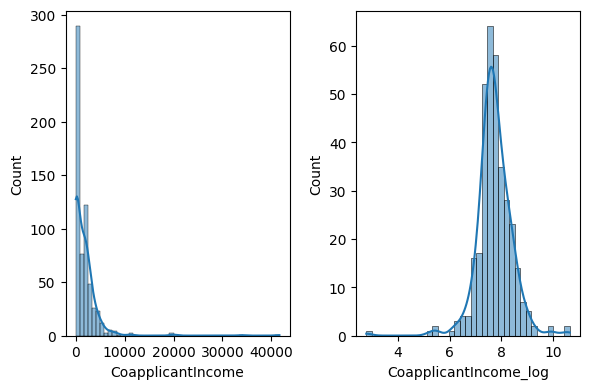

In [193]:
df['CoapplicantIncome_log'] = np.log(df['CoapplicantIncome'])
plt.figure(figsize=(6,4))
plt.subplot(1,2,1)
sns.histplot(x=df['CoapplicantIncome'], kde= True)
plt.subplot(1,2,2)
sns.histplot(x=df['CoapplicantIncome_log'], kde= True)
plt.tight_layout()

<Axes: xlabel='ApplicantIncome_exp2', ylabel='Count'>

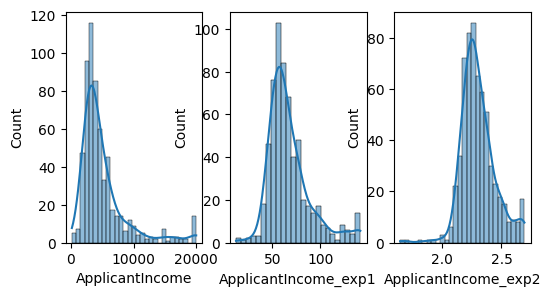

In [194]:
df['ApplicantIncome_exp1']=df.ApplicantIncome**(0.5)
df['ApplicantIncome_exp2']=df.ApplicantIncome**(0.1)
plt.figure(figsize=(6,3))
plt.subplot(1,3,1)
sns.histplot(x=df['ApplicantIncome'], kde= True)
plt.subplot(1,3,2)
sns.histplot(x=df['ApplicantIncome_exp1'], kde= True)
plt.subplot(1,3,3)
sns.histplot(x=df['ApplicantIncome_exp2'], kde= True)

In [195]:
from scipy.stats import boxcox
transformed_data, lambda_value = boxcox(df['ApplicantIncome'])
print(transformed_data)
print(lambda_value)

[8.24149172 8.02117014 7.63689595 7.50071102 8.26447795 8.17225442
 7.40794187 7.64774001 7.89935239 8.94745697 7.69554847 7.47095885
 7.65875054 7.19760511 6.87212213 8.09082113 7.80146498 7.77950231
 8.07924418 7.50668536 8.48439627 8.25768955 7.50668536 7.74120908
 7.83148231 8.683345   7.57382048 7.94777553 6.96796077 7.83949733
 7.93482689 7.68613086 8.04242934 7.77691324 8.92340347 7.38498213
 7.18518374 7.81920008 7.93482689 7.83901361 7.80247352 7.17106606
 7.43375602 7.88452952 8.04300737 7.75326906 8.21010425 8.23716344
 7.52231097 7.89799436 7.23387638 7.66258729 7.94863215 8.02765995
 8.84883645 7.54374075 7.32574325 7.74147885 8.53237304 7.73904801
 7.47095885 7.64564167 7.50983226 8.08990778 7.93482689 8.22231959
 7.69554847 8.78847052 8.41611092 7.9634917  7.69781673 7.20839644
 7.77691324 8.05449003 8.14672759 7.83949733 7.83949733 6.63153972
 7.68613086 7.73253339 7.86241422 7.43185492 6.92631489 8.26447795
 7.8952721  7.42074874 7.73253339 7.47095885 8.58483498 8.2174

<Axes: xlabel='ApplicantIncome_boxcox', ylabel='Count'>

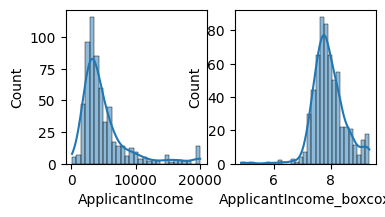

In [196]:
df['ApplicantIncome_boxcox'] = transformed_data
plt.figure(figsize=(4,2))
plt.subplot(1,2,1)
sns.histplot(x=df['ApplicantIncome'], kde= True)
plt.subplot(1,2,2)
sns.histplot(x=df['ApplicantIncome_boxcox'], kde= True)

## 4. Scaling

In [197]:
#from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved),zscore,CoapplicantIncome_log,ApplicantIncome_exp1,ApplicantIncome_exp2,ApplicantIncome_boxcox
0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y,-0.554487,-inf,76.478755,2.380719,8.241492
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,-0.038732,7.318540,67.697858,2.323352,8.021170
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,-0.554487,-inf,54.772256,2.226959,7.636896
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,0.251980,7.765569,50.823223,2.193878,7.500711
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,-0.554487,-inf,77.459667,2.386795,8.264478
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y,-0.554487,-inf,53.851648,2.219422,7.606068
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y,-0.554487,-inf,64.078077,2.297957,7.921688
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y,-0.472404,5.480639,89.844310,2.458658,8.531483
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y,-0.554487,-inf,87.080423,2.443341,8.475312


In [198]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
ApplicantIncome_scaled = scaler.fit_transform(df[['ApplicantIncome']])

In [199]:
ApplicantIncome_scaled[22:38]

array([[-0.65266533],
       [-0.4494832 ],
       [-0.35599286],
       [ 1.19589365],
       [-0.59981141],
       [-0.2208037 ],
       [-0.96022729],
       [-0.34722814],
       [-0.23673956],
       [-0.50207151],
       [-0.09703524],
       [-0.41362753],
       [ 1.97675045],
       [-0.73898453],
       [-0.85770664],
       [-0.36927274]])

In [200]:
from sklearn.preprocessing import MinMaxScaler
ApplicantIncome_scaled2 = MinMaxScaler().fit_transform(df[['ApplicantIncome']])
#ApplicantIncome_scaled2 = scaler.fit_transform(df[['ApplicantIncome']])
ApplicantIncome_scaled2[22:38]

array([[0.12342569],
       [0.16196474],
       [0.17969773],
       [0.47405542],
       [0.13345088],
       [0.20534005],
       [0.06508816],
       [0.1813602 ],
       [0.20231738],
       [0.15198992],
       [0.22881612],
       [0.16876574],
       [0.62216625],
       [0.1070529 ],
       [0.08453401],
       [0.17717884]])

In [201]:
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()
ApplicantIncome_scaled3 = scaler.fit_transform(df[['ApplicantIncome']])

### Encoding
- Converting categorical variables into numerical so that the model can process them
- OHE (one hot encoding) - Create as many columns as unique values of the categorical feature. Done to those features that cannot(shouldn't) have an ordinality.
- Label Encoding - Let the default lexicographic (alphabetical order) endocing happen. Numbers automatically assigned without any order. Renders a 1-d output (unlike all other scalers and encoders that render a 2d output) as it is designed to encode target columns
- Ordinal Encoding - Speicify the order in which numerical labels must be assigned. Done when the data is ordinal
- Frequency Encoding - Specify the order based on frequency or value_counts

In [202]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)', 'zscore', 'CoapplicantIncome_log',
       'ApplicantIncome_exp1', 'ApplicantIncome_exp2',
       'ApplicantIncome_boxcox'],
      dtype='str')

In [203]:
# OHE - One Hot Encoding
#df.Married.value_counts()
pd.get_dummies(df, columns=['Married'],dtype='int') 

,Loan_ID,Gender,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved),zscore,CoapplicantIncome_log,ApplicantIncome_exp1,ApplicantIncome_exp2,ApplicantIncome_boxcox,Married_No,Married_Yes
0,LP001002,Male,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y,-0.554487,-inf,76.478755,2.380719,8.241492,1,0
1,LP001003,Male,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,-0.038732,7.318540,67.697858,2.323352,8.021170,0,1
2,LP001005,Male,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,-0.554487,-inf,54.772256,2.226959,7.636896,0,1
3,LP001006,Male,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,0.251980,7.765569,50.823223,2.193878,7.500711,0,1
4,LP001008,Male,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,-0.554487,-inf,77.459667,2.386795,8.264478,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y,-0.554487,-inf,53.851648,2.219422,7.606068,1,0
610,LP002979,Male,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y,-0.554487,-inf,64.078077,2.297957,7.921688,0,1
611,LP002983,Male,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y,-0.472404,5.480639,89.844310,2.458658,8.531483,0,1
612,LP002984,Male,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y,-0.554487,-inf,87.080423,2.443341,8.475312,0,1


In [204]:
#OHE from sklearn
from sklearn.preprocessing import OneHotEncoder
enc = OneHotEncoder()
result = enc.fit_transform(df[['Married']]).toarray()
result

array([[1., 0.],
       [0., 1.],
       [0., 1.],
       ...,
       [0., 1.],
       [0., 1.],
       [1., 0.]], shape=(614, 2))

In [205]:
df.Married.unique()


<StringArray>
['No', 'Yes']
Length: 2, dtype: str

In [206]:
result

array([[1., 0.],
       [0., 1.],
       [0., 1.],
       ...,
       [0., 1.],
       [0., 1.],
       [1., 0.]], shape=(614, 2))

In [207]:
#Label Encoder
from sklearn.preprocessing import LabelEncoder
enc = LabelEncoder()
df['Gender_enc'] = enc.fit_transform(df.Gender)
df[['Gender','Gender_enc']]

,Gender,Gender_enc
0,Male,1
1,Male,1
2,Male,1
3,Male,1
4,Male,1
...,...,...
609,Female,0
610,Male,1
611,Male,1
612,Male,1


In [208]:
enc.fit_transform(df.Gender)

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1,
       0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1,

In [209]:
#Frequency encoding using Ordinal Encoder with value_counts
from sklearn.preprocessing import OrdinalEncoder
count=df.Gender.value_counts()
print(count)
enc = OrdinalEncoder(categories=[['Male','Female']])
df['Gender_OE1'] = enc.fit_transform(df[['Gender']])


Gender
Male      502
Female    112
Name: count, dtype: int64


In [210]:
#Ordinal Encoding
from sklearn.preprocessing import OrdinalEncoder
df.Property_Area.unique()
enc = OrdinalEncoder(categories=[['Rural','Semiurban','Urban']])
df['OE_Prop_Area'] = enc.fit_transform(df[['Property_Area']])
df[['Property_Area','OE_Prop_Area']]

,Property_Area,OE_Prop_Area
0,Urban,2.0
1,Rural,0.0
2,Urban,2.0
3,Urban,2.0
4,Urban,2.0
...,...,...
609,Rural,0.0
610,Rural,0.0
611,Urban,2.0
612,Urban,2.0


In [211]:
#Frequency encoding using Ordinal Encoder with value_counts
from sklearn.preprocessing import OrdinalEncoder
df.Gender.value_counts()
enc = OrdinalEncoder(categories=[['Male','Female']])
df['Gender_OE1'] = enc.fit_transform(df[['Gender']])

In [212]:
df.Gender_OE1

0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
609    1.0
610    0.0
611    0.0
612    0.0
613    1.0
Name: Gender_OE1, Length: 614, dtype: float64

In [213]:
enc.fit_transform(df[['Gender']])

array([[0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],

---


In [214]:
df['Gender_freq']=df['Gender'].map(df['Gender'].value_counts())
print(df['Gender_freq'])

0      502
1      502
2      502
3      502
4      502
      ... 
609    112
610    502
611    502
612    502
613    112
Name: Gender_freq, Length: 614, dtype: int64
